# Samuel — Autonomous Regression Research

KASDAD TP2 · Prediction calibration, text information and temporal generalization

## Motivation & hypotheses

The initial R1-D public MAE was13.53473 versus the user-supplied official baseline12.23275. This phase asks whether prediction-only cycle ranking, text features and a simple stronger estimator improve MAE while preserving temporal evaluation and explainability. The formal EDA question remains unchanged.

## Context & Methods

Same six expanding 4-cycle windows and two H12 views. Each family has38,588 validation records; H12 reuses primary records. Prior EDA/rounds have used all these cycles, so evidence is adaptive development, not an untouched test. Stage-specific protocols/code/input identities are frozen before each stage. Mapping weights and LightGBM complexities use only past inner labels.

### Key assumptions

Prediction-only percentile mapping uses all supplied rows of a cycle and average ties. Supplied batches may not exhaust the real source universe. It does not prove the official target generator. Added structured/text features retain supplied-schema eligibility with operational timing provisional. No Test labels or fabricated zero-cohort labels are used. Public Kaggle feedback is limited and separate; no more than six additional regression submissions are authorized.

In [1]:
from pathlib import Path
import sys,json,hashlib
import pandas as pd
from IPython.display import display,Image

ROOT=Path.cwd().resolve()
while not (ROOT/'src/utils/paths.py').exists() and ROOT!=ROOT.parent: ROOT=ROOT.parent
if not (ROOT/'src/utils/paths.py').exists(): raise FileNotFoundError('Open inside the TP2 repository.')
sys.path.insert(0,str(ROOT))
from src.models.regression_research_common import verify_stage
from scripts.report_regression_research import load_stages,comparisons,build
for stage in ['stage1_ranking','stage23_models','stage4_refinement','stage5_lgb_text','shift_diagnostics','scope_sensitivity']:
    receipt=verify_stage(stage)
    print(stage,receipt['signature'][:16],len(receipt['protected_files']),'protected files')
stages=load_stages();comparison=comparisons(stages)
print('Prediction caches are local and ignored; no model weights are committed.')

stage1_ranking 55bddf24acc4f69b 242 protected files


stage23_models 052610c2adef6ad1 248 protected files


stage4_refinement e923498857a78827 263 protected files


stage5_lgb_text 22aaf721983445fe 276 protected files


shift_diagnostics 89cf27f528270d50 248 protected files


scope_sensitivity cd4dd0ac87cadb64 276 protected files


Prediction caches are local and ignored; no model weights are committed.


## tl;dr

Pure percentile ranking harms the original structured controls. Text adds information, and mapping helps compressed Ridge scores more than HGB scores. SVD32+LightGBM has the lowest observed primary MAE; hybrid Ridge remains the lowest pooled H12 candidate. The exact current public scores are shown separately below; neither internal winner nor public winner is automatically final.

,Stage,Recipe,Policy,Primary MAE,Equal-cycle MAE,H12 MAE,H12_E,H12_L
0,stage1_ranking,R1_C,raw,15.14899,15.25409,15.47789,16.43213,14.67056
6,stage1_ranking,R1_D,raw,13.34984,13.58966,15.57724,17.79560,13.70039
12,stage1_ranking,B_D_RECENT8,raw,13.21715,13.50710,15.79456,17.88721,14.02408
18,stage1_ranking,A_NO_CODES,raw,14.07860,14.19002,15.05347,16.13209,14.14090
27,stage23_models,text_ridge,inner,18.27484,18.46576,19.47479,21.44080,17.81145
31,stage23_models,hybrid_ridge,inner,12.55130,12.79007,13.93812,16.39546,11.85908
35,stage23_models,svd_hgb,inner,12.36618,12.67774,14.71412,17.27256,12.54955
39,stage23_models,lgb_inner,inner,13.06489,13.32251,15.60415,17.88659,13.67310
41,stage4_refinement,svd128,inner,12.29935,12.61807,14.64843,17.18842,12.49948
43,stage4_refinement,svd_noscope32,inner,12.35219,12.67379,14.73983,17.33736,12.54218


Built 7 figures and 48 comparison rows


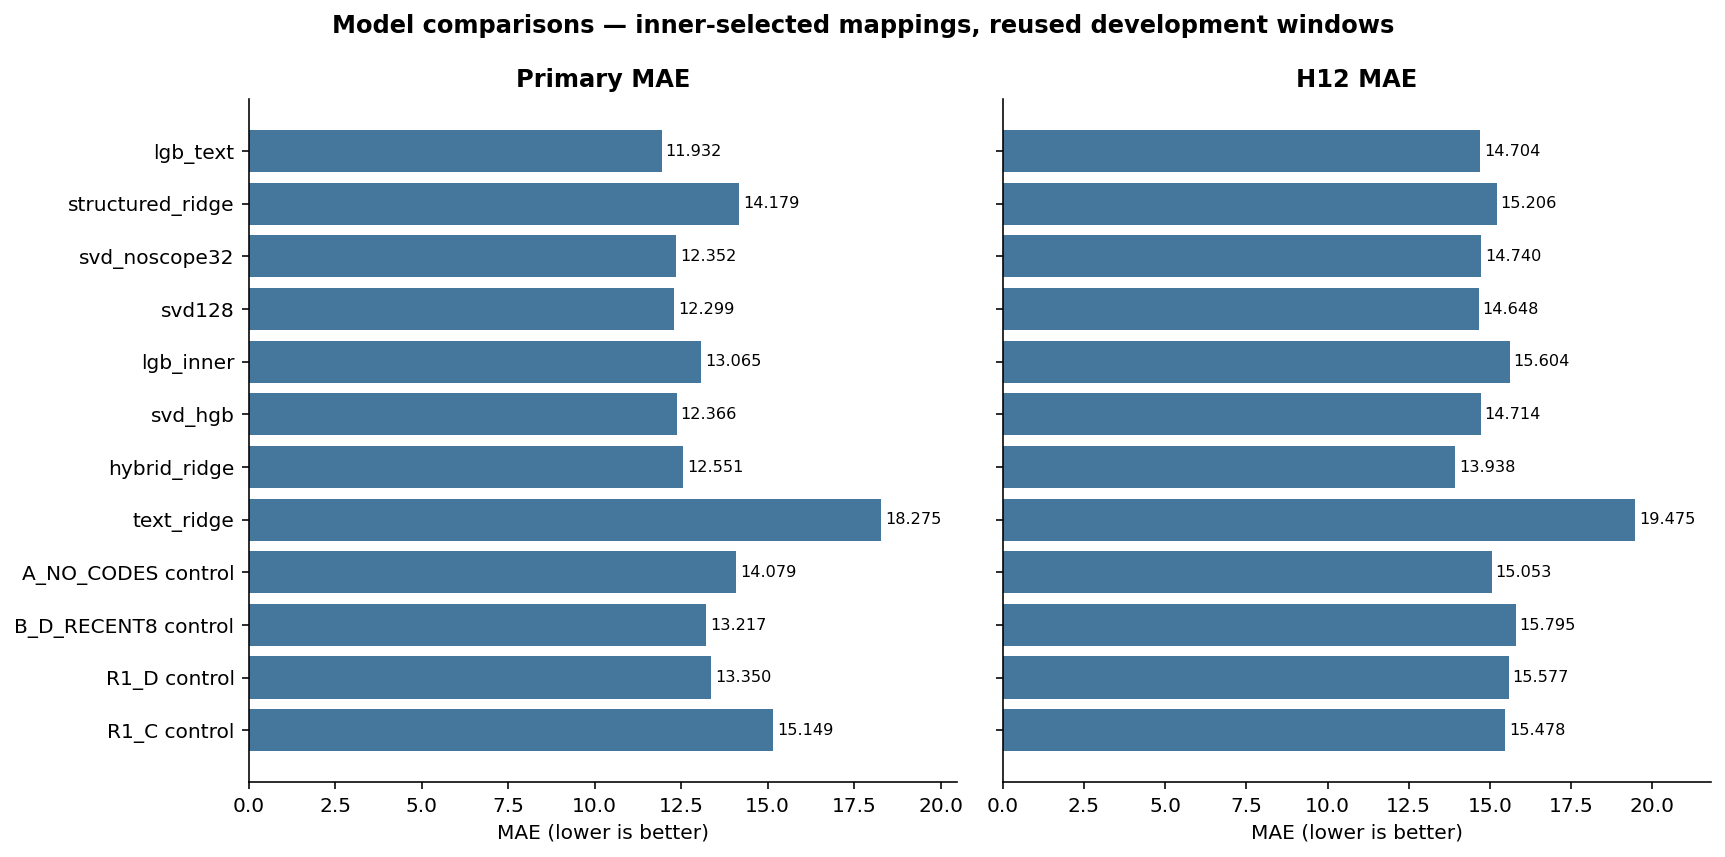

In [2]:
cols=['Stage','Recipe','Policy','Primary MAE','Equal-cycle MAE','H12 MAE','H12_E','H12_L']
display(comparison[(comparison.Policy=='inner')|((comparison.Stage=='stage1_ranking')&(comparison.Policy=='raw'))][cols].round(5))
figures=build()
display(Image(filename=str(ROOT/'reports/regression_research/figures/research_model_comparison.png')))

## Results — prediction-only cycle ranking

These weights were fixed before outer evaluation. They are diagnostic comparisons, not per-window oracle selection. Pure ranking changes score spacing and marginal distribution; it cannot repair ranking inversions. Incomplete-reference stress compares a subset against the complete supplied-cycle map on identical retained rows.

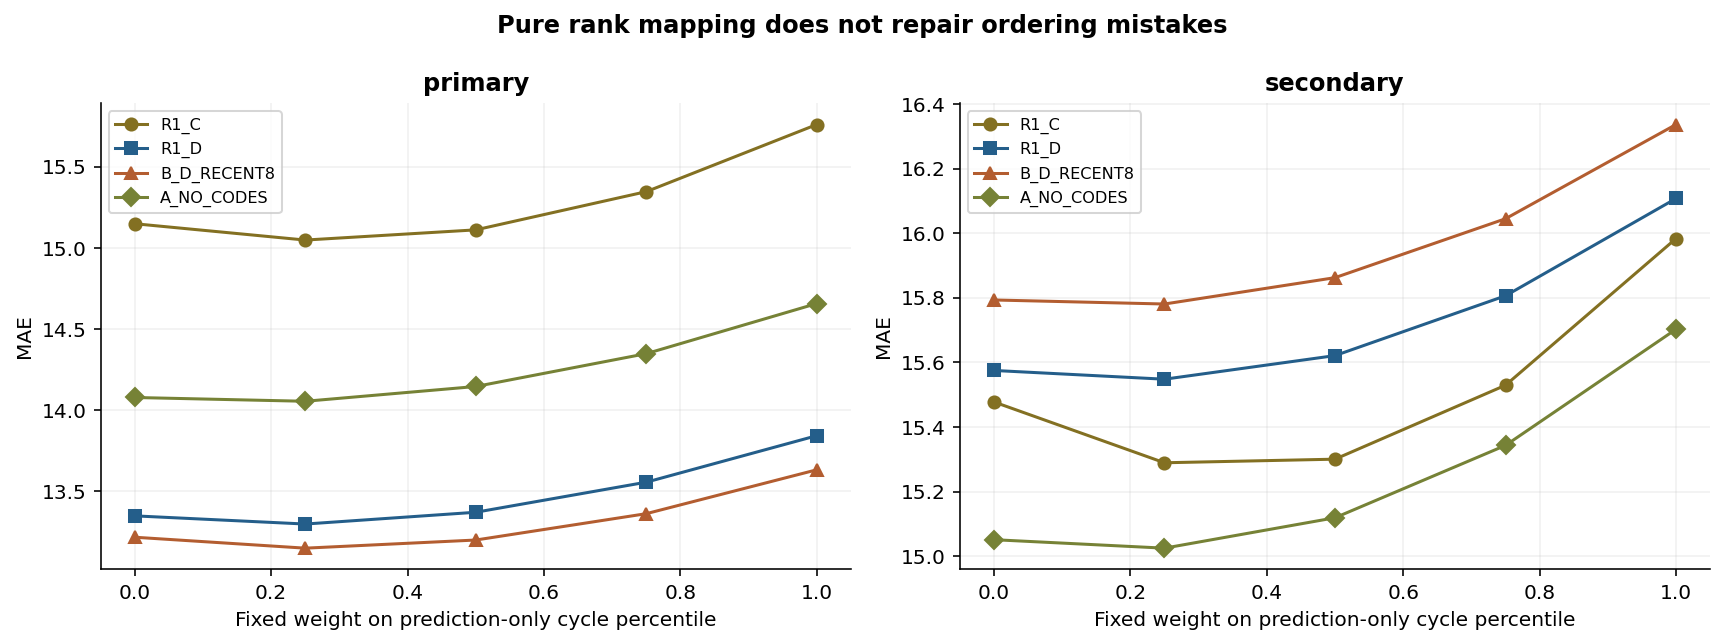

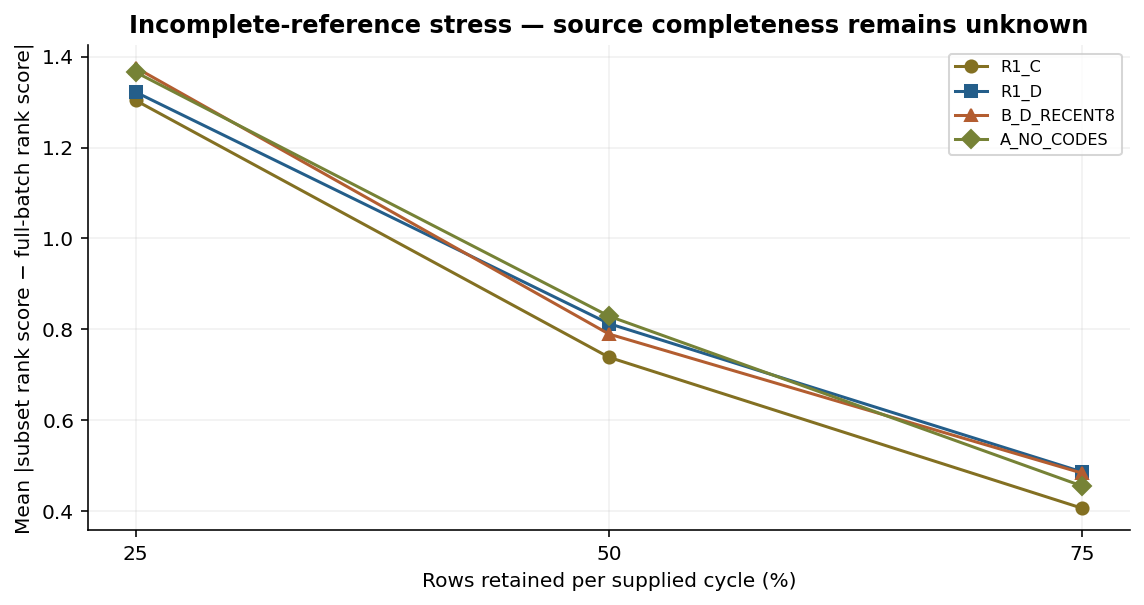

In [3]:
display(Image(filename=str(ROOT/'reports/regression_research/figures/research_rank_mapping.png')))
display(Image(filename=str(ROOT/'reports/regression_research/figures/research_batch_sensitivity.png')))

## Results — text and model contribution

Text-only Ridge is weak. Same-family structured Ridge is a meaningful negative control: its imputer/scaler/OHE/alpha are identical to hybrid Ridge, but every stream is replaced with a constant empty string during fit and prediction. Hybrid's gain therefore includes text plus availability information. HGB+SVD retains the original native structured categories. LightGBM uses the same SVD32 representation, isolating the model×information interaction without a new text vocabulary recipe.

Stage4 tested128 latent dimensions, no-scope representation and the structured Ridge control. Stage5 reused two previously defined LightGBM complexities; inner validation chose parameters and rank weight jointly. No deep architecture, stacking or large ensemble was used.

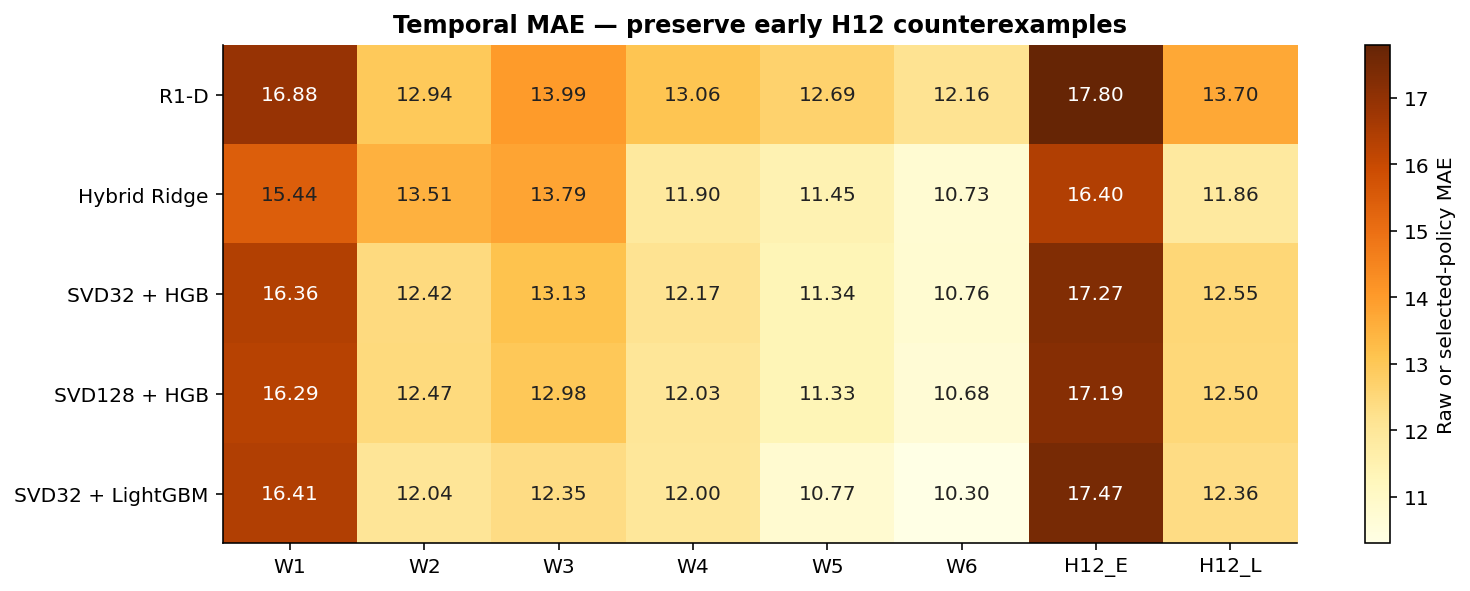

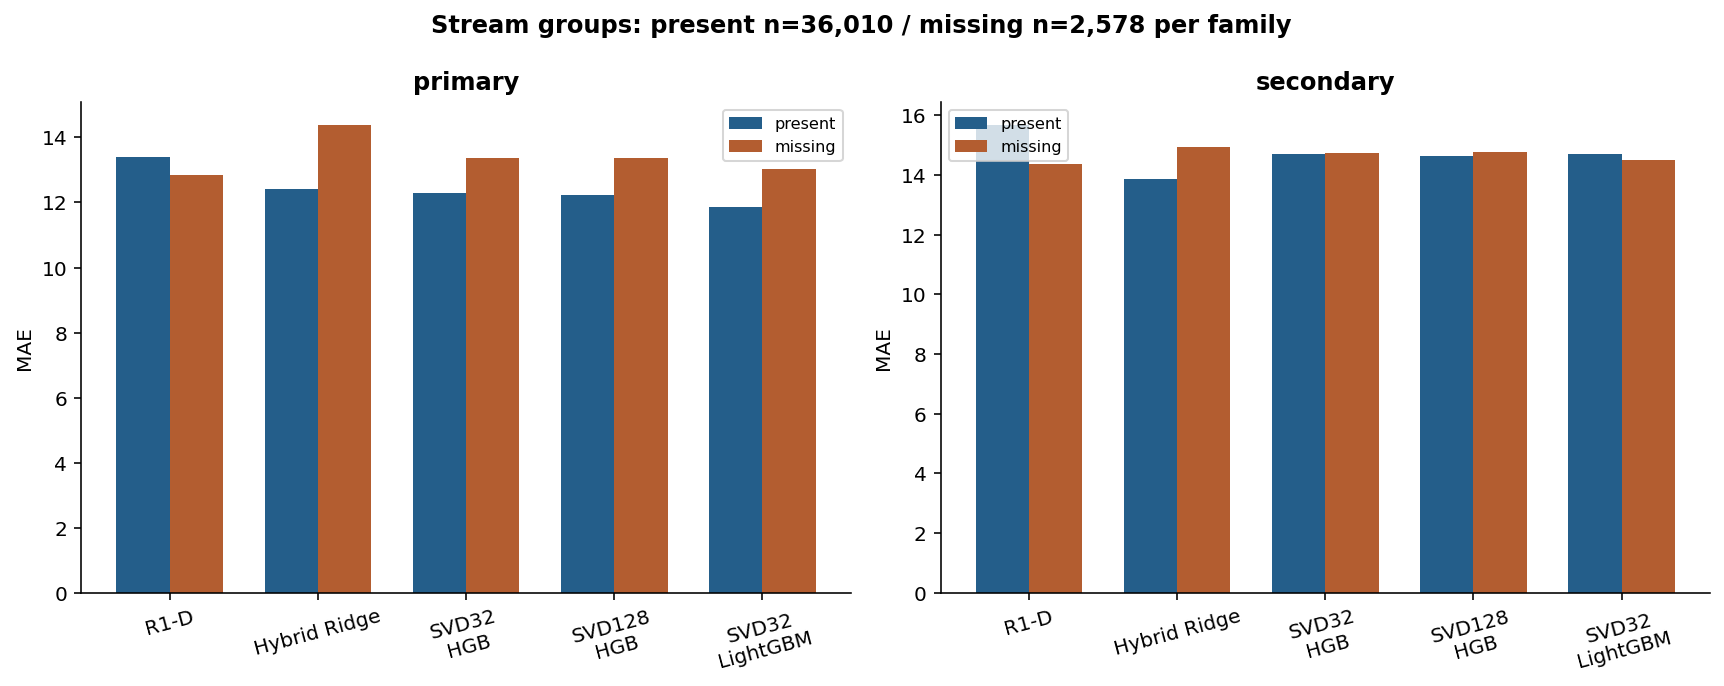

In [4]:
display(Image(filename=str(ROOT/'reports/regression_research/figures/research_window_heatmap.png')))
display(Image(filename=str(ROOT/'reports/regression_research/figures/research_stream_subgroups.png')))

## Results — errors and target geometry

Actual target bins and tails are evaluation-only; they never select an inference gate. Absolute-error fitting remains median-oriented. A compressed conditional prediction distribution need not copy the outcome distribution: broad conditional spread can reflect uncertainty or unmeasured heterogeneity. Ranking/calibration that improves tails can still worsen central MAE or missing-stream performance.

,Recipe,Primary MAE,RMSE,Bias,EF0,EF1,Low tail,High tail,Missing,Present,Spearman
27,text_ridge,18.27484,23.01065,-0.20968,18.44555,17.92024,23.84130,22.71925,23.71645,17.88527,0.61356
31,hybrid_ridge,12.55130,16.57648,-0.66450,13.76768,10.02465,10.83168,9.55167,14.36961,12.42113,0.82431
35,svd_hgb,12.36618,16.53960,-0.39238,13.47716,10.05846,13.42466,10.22986,13.35450,12.29543,0.82140
39,lgb_inner,13.06489,17.36875,-0.16626,14.24852,10.60627,15.16925,10.47478,12.73007,13.08886,0.80294
41,svd128,12.29935,16.49217,-0.44632,13.41419,9.98363,13.00186,10.06340,13.35218,12.22398,0.82271
43,svd_noscope32,12.35219,16.53547,-0.37530,13.42725,10.11907,13.37590,10.26893,13.30678,12.28385,0.82142
45,structured_ridge,14.17865,18.01531,-0.73447,15.60152,11.22309,16.24683,11.93133,14.21848,14.17580,0.78505
47,lgb_text,11.93160,16.25665,-0.41816,12.97905,9.75585,12.23539,9.49544,13.04181,11.85212,0.82942


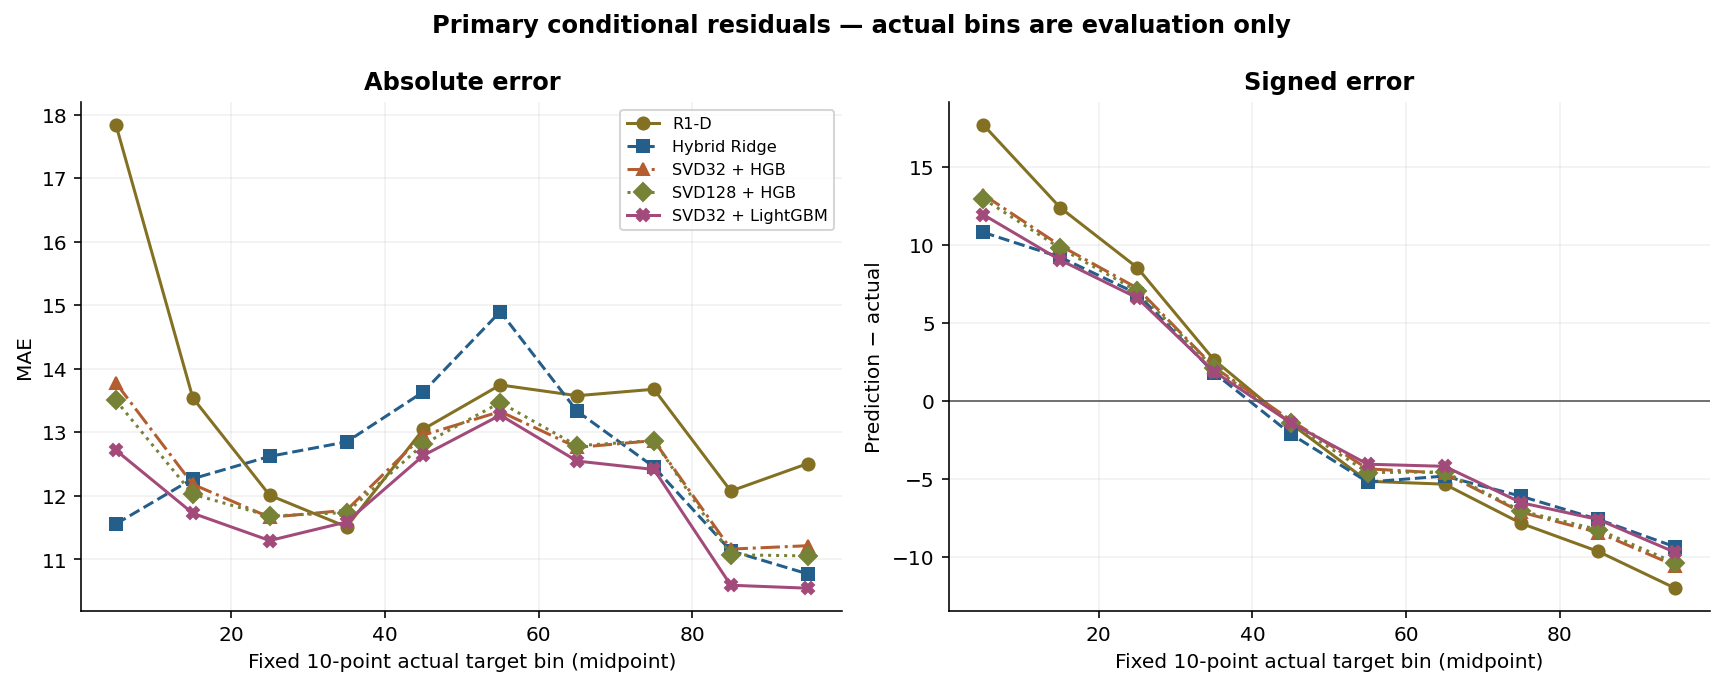

In [5]:
display(comparison[comparison.Policy=='inner'][['Recipe','Primary MAE','RMSE','Bias','EF0','EF1','Low tail','High tail','Missing','Present','Spearman']].round(5))
display(Image(filename=str(ROOT/'reports/regression_research/figures/research_residuals.png')))

## Results — novel scope support

No Train count is zero;6,278 Test rows have at least one scope/spread zero and all lie below the Train pressure minimum. Zero parses as numeric but its semantics are unknown. No zero-to-median replacement was applied. The no-scope validation ablation was not a consistent winner.

The unscored sensitivity probe sets three counts to zero and pressure below Train support on copied validation inputs. Its prediction deltas quantify model reliance under an artificial input scenario. Labels may no longer describe that altered record, so no perturbed MAE is computed and no claim is made about Test zero-cohort accuracy.

In [6]:
shift=json.loads((ROOT/'reports/regression_research/shift_diagnostics.json').read_text(encoding='utf-8'))
sensitivity=json.loads((ROOT/'reports/regression_research/scope_sensitivity.json').read_text(encoding='utf-8'))
print('See SHIFT_DIAGNOSTICS.md for exact source identities and predictor-only evidence.')
display(pd.Series({k:v for k,v in sensitivity.items() if not isinstance(v,(dict,list))}))
print('Unscored sensitivity report:',ROOT/'reports/regression_research/scope_sensitivity.json')

See SHIFT_DIAGNOSTICS.md for exact source identities and predictor-only evidence.


status                                                         VALID_UNSCORED_SENSITIVITY_ONLY
stage                                                                        scope_sensitivity
generated_at_utc                                              2026-10-30T15:38:26.147112+00:00
freeze_signature                             cd4dd0ac87cadb642f85411f1df38dcedfe39dc1f89a00...
source_head                                           88aa1e9e78cf0056875e96e3e1b4792d57e080dd
train_file_sha256_verified                   756523ff8156a9cd776e52249f7e2a8f23dcec432b8d10...
fit_rows                                                                                 29705
fit_positions_sha256                         21df8b3baa7004c330d6ac403ed42e8cbd9de99081d048...
validation_rows                                                                          20903
validation_positions_sha256                  9ead64310afbcc9fd5ef149b46a920a7dd2062debc58cf...
validation_labels_used_for_metrics_or_fit         

Unscored sensitivity report: C:\Users\Sam\OneDrive\Documents\KASDAD\TP 2\reports\regression_research\scope_sensitivity.json


## Results — limited Kaggle feedback

Each shown additional candidate has a recorded recipe, full-Train fit, validated29,421-row CSV, input/output hashes and an at-most-once submission reservation. CSVs remain ignored. Public scores cover only the public subset; the user describes roughly30% public/70% private, and private scores remain unavailable. Candidate recipes were not refit to public labels, and remaining authorization is not a quota to consume.

,candidate,public MAE,Kaggle ref
0,Initial R1-D,13.53473,None
1,hybrid_ridge_inner_v1,12.55466,57809775
2,svd_hgb_inner_v1,12.34519,57809802
3,svd128_inner_v1,12.38411,57810028
4,lgb_text_inner_v1,11.71363,57810150


Official baseline (user supplied):12.23275


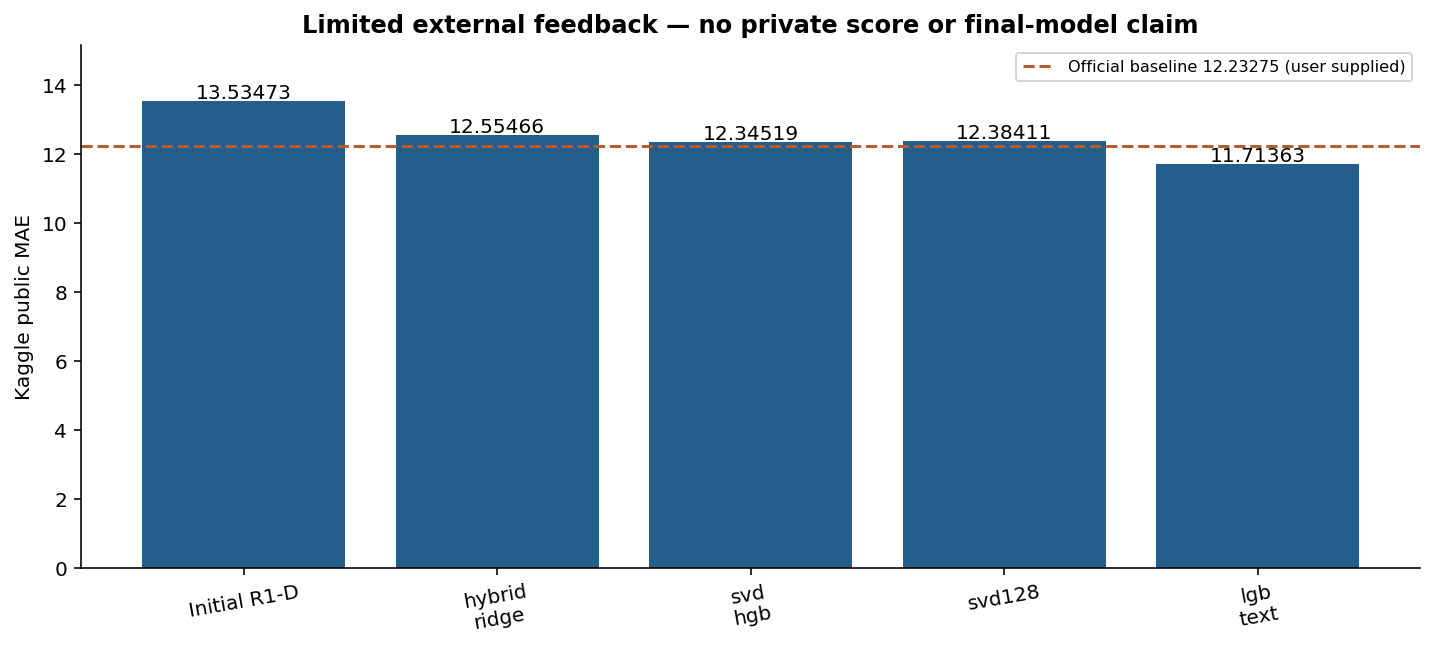

In [7]:
data=json.loads((ROOT/'reports/regression_research/report_data.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'candidate':k,'public MAE':v,'Kaggle ref':data['kaggle_refs'].get(k)} for k,v in data['kaggle_scores'].items()]))
print('Official baseline (user supplied):12.23275')
display(Image(filename=str(ROOT/'reports/regression_research/figures/research_kaggle_scores.png')))

## Interpretation, limitations & next steps

Read [FINDINGS.md](../../reports/regression_research/FINDINGS.md) for the final evidence-led review, counterexamples and recommended next step. [COMPARISON_TABLES.md](../../reports/regression_research/COMPARISON_TABLES.md) keeps all fixed and inner-selected candidates. The formal EDA's conditional shifts remain valid; predictive improvements do not identify the target-generation formula or resolve source semantics.

No permanent final model decision or Classification optimization follows automatically. Review H12 early risk, EF/tails, missing text and provided-batch assumptions alongside the public benchmark. Further work should be a single justified hypothesis with fixed guardrails, rather than small leaderboard-driven changes.

## Checks

The independent verifier recomputes mappings using pandas ranks and checks saved fit/validation row positions, fingerprints, inner choices, MAE/bias/tails/EF/cycle metrics and subgroup support. It does not refit models or read Test labels.

In [8]:
checks=[]
for name in ['stage1','stage23','stage4','stage5']:
    r=json.loads((ROOT/f'reports/regression_research/verification_{name}.json').read_text(encoding='utf-8'))
    assert r['status']=='PASS'
    checks.append({'stage':name,'status':r['status'],'checks':str(r.get('checks',{}))[:260]})
display(pd.DataFrame(checks))
print('No training, upload, threshold selection or Test prediction occurs in this notebook.')

,stage,status,checks
0,stage1,PASS,{'freeze': {'freeze_signature': '55bddf24acc4f...
1,stage23,PASS,{'freeze': {'freeze_signature': '052610c2adef6...
2,stage4,PASS,{'freeze': {'freeze_signature': 'e923498857a78...
3,stage5,PASS,{'freeze': {'freeze_signature': '22aaf72198344...


No training, upload, threshold selection or Test prediction occurs in this notebook.
